# 01. Разведочный анализ

**Цель блокнота** — познакомиться с данными до любых выводов: сколько их, какого они качества, как устроены.

Здесь мы ничего не доказываем. Наблюдения из этого блокнота — это гипотезы, которые проверяются в `02_analysis.ipynb`.

**Данные:** 344 пингвина трёх видов с архипелага Палмер (Антарктида), Horst, Hill, Gorman (2020). Файл скачивается и очищается конвейером `python -m palmer_penguins.pipeline`.

In [9]:
# Расширение autoreload перезагружает изменённые модули проекта перед каждой ячейкой.
# Без него правки в src/palmer_penguins/*.py не были бы видны до перезапуска ядра.
%load_ext autoreload
%autoreload 2

import pandas as pd
import seaborn as sns

from palmer_penguins.data import PROJECT_ROOT, load_clean, load_raw

FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Сырые данные: что лежит в файле

Начинаем с **неочищенных** данных: важно увидеть проблемы источника своими глазами, прежде чем их исправлять.

In [10]:
raw = load_raw()

raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [11]:
raw.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

У 2 птиц нет ни одного измерения (по 2 пропуска в каждом числовом столбце - это одни и те же две строки), а пол неизвестен у 11. Поэтому в функции `clean` строки без измерений удаляются, но пропуски пола остаются и отбрасываются только там, где пол нужен.

In [12]:
raw["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

## 2. Очищенные данные: как устроены виды

Дальше работаем с очищенной таблицей. Её создаёт конвейер, а `load_clean` читает её и восстанавливает категориальные типы столбцов.

In [13]:
df = load_clean()

df.groupby("species", observed=True)[
    ["bill_length_mm", "bill_depth_mm", "body_mass_g"]
].mean().round(1)

,bill_length_mm,bill_depth_mm,body_mass_g
species,,,
Adelie,38.8,18.3,3700.7
Chinstrap,48.8,18.4,3733.1
Gentoo,47.5,15.0,5076.0


Виды отличаются по-разному:
- у **Gentoo** клюв длинный (≈47.5 мм) и неглубокий (≈15.0 мм), и сами они самые тяжёлые (≈5.1 кг);
- у **Adelie** клюв короткий (≈38.8 мм) и глубокий (≈18.3 мм);
- **Chinstrap** - длинный (≈48.8 мм) и глубокий (≈18.4 мм) клюв.

Похоже, что по двум размерам клюва виды хорошо различимы - это вопрос 3 в `02_analysis`.

In [14]:
pd.crosstab(df["species"], df["island"])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


Gentoo живут только на острове Biscoe, Chinstrap - только на Dream. По этим данным эффект острова нельзя отделить от эффекта вида. Утверждение "пингвины с Biscoe тяжелее" на самом деле говорило бы о Gentoo.

## 3. Все признаки на одной картинке

Построим диаграмму рассеяния для каждой пары числовых признаков.

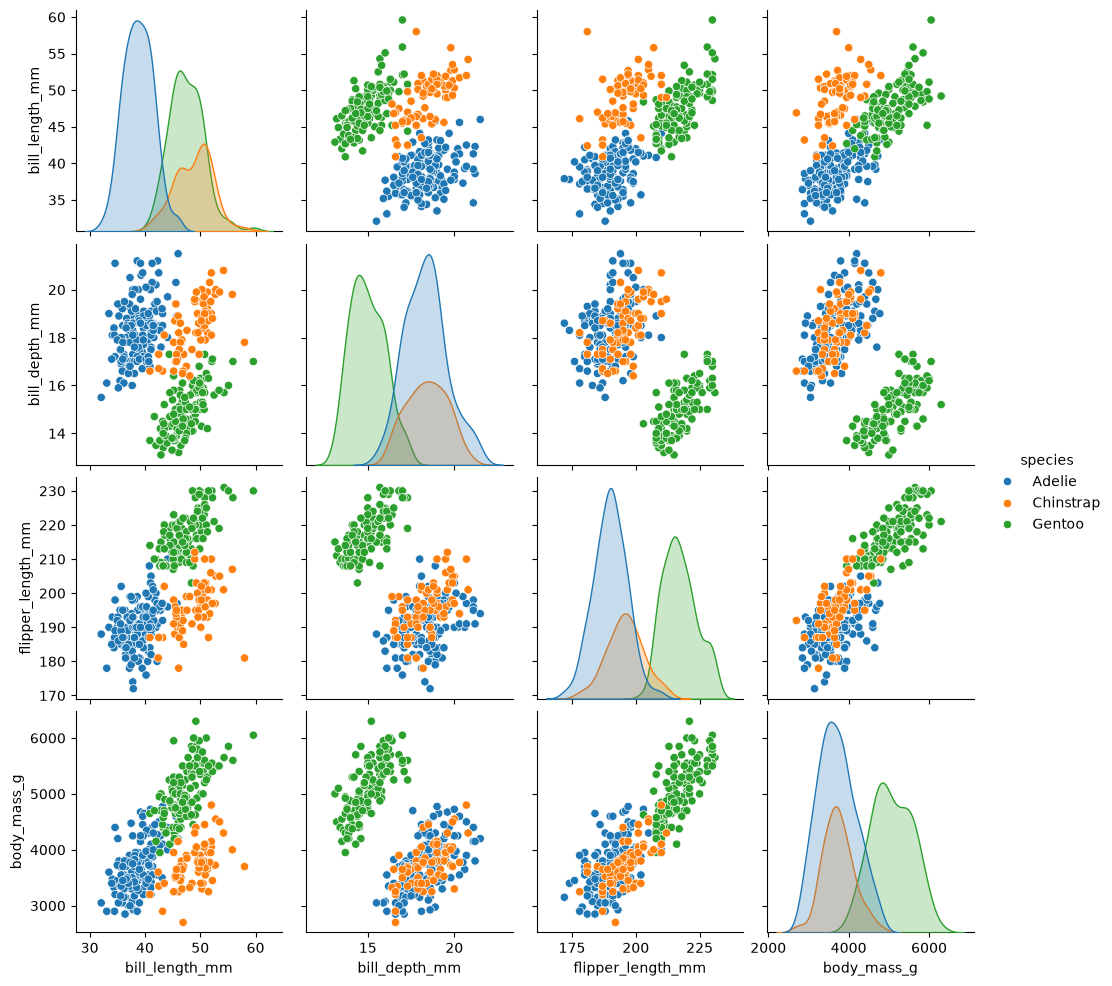

In [15]:
g = sns.pairplot(
    df,
    hue="species",
    vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"],
)

g.savefig(FIG / "pairplot.png", dpi=100)

## Итоги разведки

1. Данные почти чистые (2 строки без измерений и 11 пропусков пола).
2. Классы не сбалансированы: Adelie 152, Gentoo 124, Chinstrap 68.
3. Выводы об островах по этим данным делать нельзя.
4. На диаграмме "длина × глубина клюва" три вида образуют три почти раздельных облака - гипотеза для вопроса 3.
5. Внутри каждого облака длина и глубина клюва, кажется, растут вместе, а по всем птицам сразу облака выстроены "наоборот" - гипотеза для вопроса 1 (парадокс Симпсона).